### <b>8강 관계와 추세 그래프 - scatterplot · regplot · lmplot · lineplot</b>

* <b>scatterplot</b>은 두 수치의 관계를 점으로 그리고, 세 번째 변수를 <b>hue</b>(색)와 <b>size</b>(점 크기)로 더한다. 4강 기온-에이드 산점도의 두 갈래를 색으로 나눠 본다.
* <b>regplot</b>·<b>lmplot</b>은 점 위에 회귀선(추세선)을 긋고, <b>corr()</b>로 구한 <b>상관계수</b>가 그 관계의 방향과 강도를 숫자로 보여 준다. 추세선은 방향을 보여 줄 뿐 원인을 말하지 않는다.
* <b>lineplot</b>은 x값마다 값이 여러 개면 평균선과 신뢰구간 띠를 함께 그린다. 일별 값의 출렁임은 <b>rolling(7).mean()</b>(7일 이동평균)으로 걸러 추세만 남긴다.

* 첫 코드 셀은 6강에서 정한 <b>설정 셀</b> 그대로다.
  * <b>sns.set_theme(...)</b>에 한글 폰트와 마이너스 설정을 함께 넘긴다. 그래프 글자가 깨지면 이 셀을 다시 실행한다.

In [1]:
# keep
import platform
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if platform.system() == 'Windows':
    font_name = 'Malgun Gothic'
else:
    font_name = 'AppleGothic'
sns.set_theme(style='whitegrid', font=font_name, rc={'axes.unicode_minus': False})

* 오늘은 두 파일을 모두 쓴다. 2강과 같은 방법으로 읽는다.
  * <b>students</b>: 학생 300명의 생활 습관 설문(가상), 학생 1명 = 1행
  * <b>cafe</b>: 캠퍼스 카페 1년 일별 판매(가상), 하루 = 1행
* 범주 순서 리스트도 7강과 같이 미리 만들어 둔다.

In [2]:
# keep
students = pd.read_csv('../data/students.csv')
cafe = pd.read_csv('../data/cafe_sales.csv', parse_dates=['date'])
print(students.shape, cafe.shape)

major_order = ['공학', '자연과학', '사회과학', '인문', '예체능']
weekday_order = ['월', '화', '수', '목', '금', '토', '일']
period_order = ['1학기', '여름방학', '2학기', '겨울방학']

(300, 12) (365, 14)


#### <b>1) 전공별 색을 넣은 공부 시간-점수 산점도</b>

* 4강에서는 <b>ax.scatter(x값, y값)</b>에 두 열의 값을 꺼내 넘겼다.
* <b>sns.scatterplot(data=표, x='열', y='열')</b>: 표와 열 이름만 넘기면 한 행을 점 하나로 찍는다.
  * 4강의 <b>s</b>(점 크기)·<b>alpha</b>(투명도)도 그대로 넘길 수 있다.
  * 다른 Seaborn 함수처럼 <b>ax=</b>로 그릴 칸을 정하고, 축 이름은 열 이름이 저절로 붙는다.
* 두 방법을 1×2 칸에 나란히 그려 비교한다.

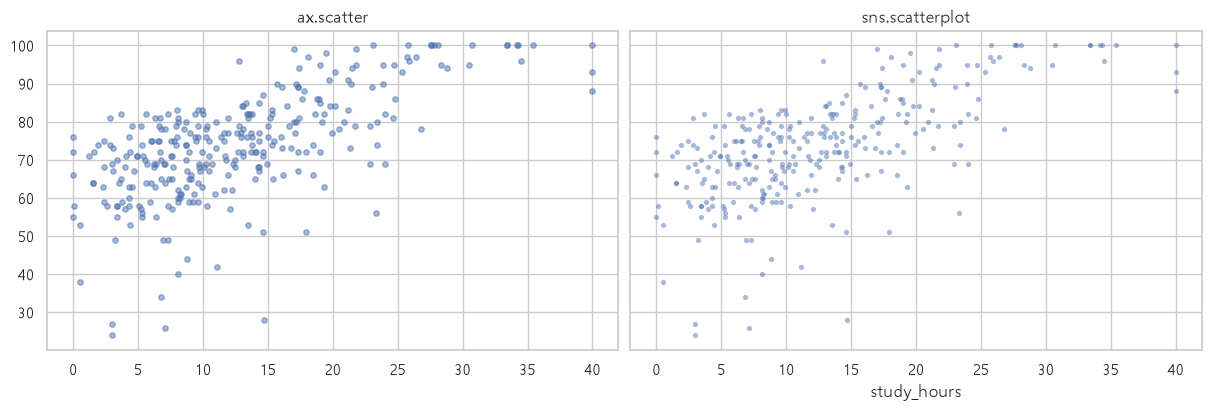

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout='constrained')
axes[0].scatter(students['study_hours'], students['exam_score'], s=15, alpha=0.5)
axes[0].set_title('ax.scatter')
sns.scatterplot(data=students, x='study_hours', y='exam_score', s=15, alpha=0.5, ax=axes[1])
axes[1].set_title('sns.scatterplot')
plt.show()

* 두 그래프의 점 300개는 같은 자리에 찍힌다. 오른쪽 칸에는 study_hours·exam_score 축 이름이 저절로 붙었다.
* 점 무리가 왼쪽 아래에서 오른쪽 위로 기운다(4강). 이 점들에 <b>세 번째 변수</b>를 더해 본다.
* <b>hue='major'</b>: 전공마다 점 색을 다르게 칠한다(6·7강의 hue와 같다).
  * <b>hue_order=major_order</b>: 범례와 색을 공학 → 예체능 순서로 놓는다. 빼면 표에 처음 나온 순서다.

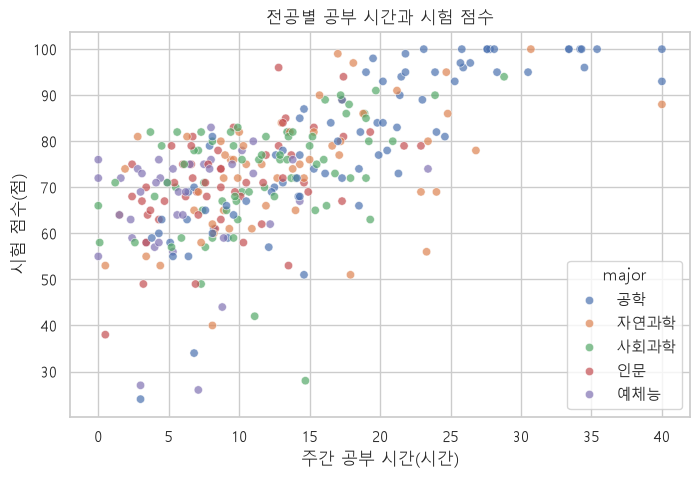

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=students, x='study_hours', y='exam_score',
                hue='major', hue_order=major_order, alpha=0.7, ax=ax)
ax.set_title('전공별 공부 시간과 시험 점수')
ax.set_xlabel('주간 공부 시간(시간)')
ax.set_ylabel('시험 점수(점)')
plt.show()

* 그래프에서 읽을 것
  * 공학 점이 오른쪽(공부 시간이 긴 쪽)에 많이 퍼져 있고, 예체능 점은 왼쪽 10시간 아래에 몰려 있다. 6·7강 박스플롯에서 본 공부 시간 차이가 산점도에서도 보인다.
  * 전공이 달라도 오른쪽 위로 기우는 방향은 같다.
* <b>size='part_time_hours'</b>: 주간 아르바이트 시간이 길수록 점을 크게 그린다. 이제 한 그래프에 변수가 네 개(x·y·색·크기)다.
  * 범례가 전공 다섯 줄과 크기 여섯 줄로 길어진다. <b>sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1))</b>로 범례를 그래프 바깥 오른쪽 위로 옮겨 점을 가리지 않게 한다.

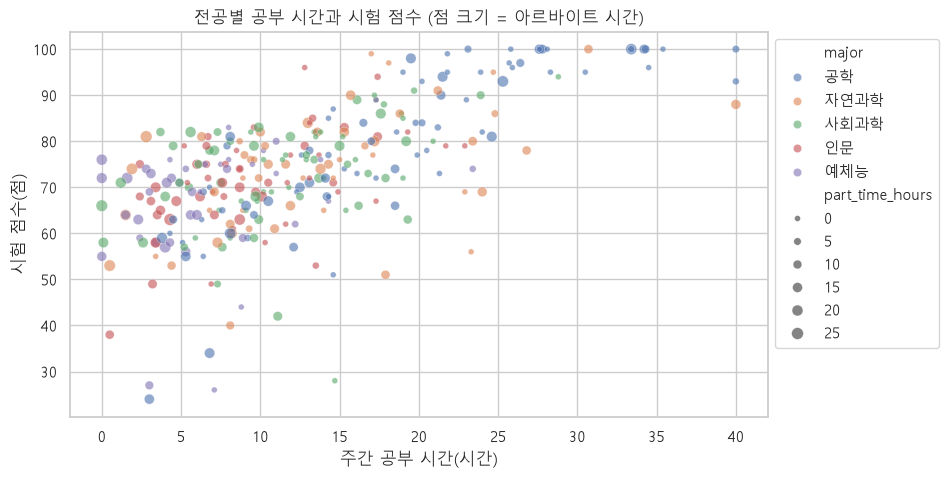

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=students, x='study_hours', y='exam_score',
                hue='major', hue_order=major_order, size='part_time_hours', alpha=0.6, ax=ax)
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1))
ax.set_title('전공별 공부 시간과 시험 점수 (점 크기 = 아르바이트 시간)')
ax.set_xlabel('주간 공부 시간(시간)')
ax.set_ylabel('시험 점수(점)')
plt.show()

* 큰 점(아르바이트를 오래 하는 학생)이 왼쪽에 조금 더 많다. 아르바이트 시간과 공부 시간은 약한 음의 관계다(아래 2)에서 숫자로 확인).
* 하지만 색과 크기를 함께 읽기는 어렵다. 크기는 차이를 눈으로 비교하기 힘들고, 점이 커질수록 서로 가린다.
  * 산점도에 더하는 변수는 <b>두 개(색 하나, 크기 하나)까지</b>만 권한다. 하나로 충분하면 하나만 쓴다.

* 이제 4강의 기온-에이드 산점도로 돌아간다. 10°C 무렵부터 점이 위아래 두 갈래로 벌어졌고, 위 갈래는 학기 평일, 아래 갈래는 주말·방학이라고 읽었다.
* 이것을 색으로 확인하려면 hue에 넣을 열이 필요하다. period(학사 기간) 열은 학기 주말도 '1학기'·'2학기'라서 두 갈래와 딱 맞지 않는다.
* 2강의 <b>.loc</b>으로 새 열 <b>day_type</b>을 만든다.
  * 먼저 모든 날을 '주말·방학'으로 채운다.
  * period가 1학기·2학기이고(<b>isin</b>) 요일이 토·일이 아닌(<b>~</b>, 조건 뒤집기) 날만 '학기 평일'로 바꾼다.

In [6]:
cafe['day_type'] = '주말·방학'
cafe.loc[cafe['period'].isin(['1학기', '2학기']) & ~cafe['weekday'].isin(['토', '일']), 'day_type'] = '학기 평일'
day_type_order = ['학기 평일', '주말·방학']

cafe['day_type'].value_counts()

day_type
주말·방학    205
학기 평일    160
Name: count, dtype: int64

* 학기 평일 160일, 주말·방학 205일이다.
* hue를 period로 준 그래프와 day_type으로 준 그래프를 1×2로 나란히 그려, 어느 열이 두 갈래를 나누는지 비교한다.

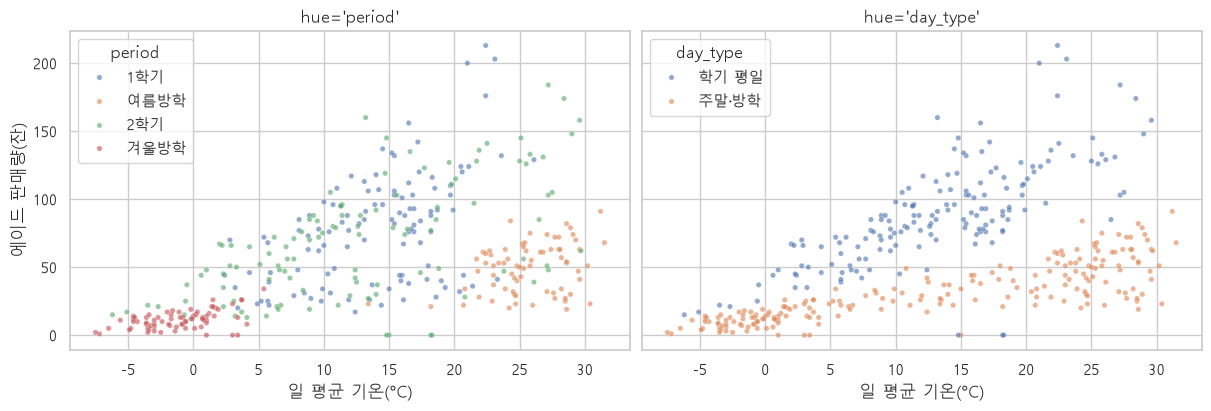

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout='constrained')
sns.scatterplot(data=cafe, x='avg_temp', y='ade', hue='period', hue_order=period_order,
                s=15, alpha=0.6, ax=axes[0])
axes[0].set_title("hue='period'")
sns.scatterplot(data=cafe, x='avg_temp', y='ade', hue='day_type', hue_order=day_type_order,
                s=15, alpha=0.6, ax=axes[1])
axes[1].set_title("hue='day_type'")
axes[0].set_xlabel('일 평균 기온(°C)')
axes[1].set_xlabel('일 평균 기온(°C)')
axes[0].set_ylabel('에이드 판매량(잔)')
plt.show()

* 그래프에서 읽을 것
  * 왼쪽(period): 1학기·2학기 색 점이 위 갈래와 아래 갈래에 모두 있다. 학기 주말이 아래 갈래에 섞여서다.
  * 오른쪽(day_type): 위 갈래는 거의 학기 평일 색, 아래 갈래는 거의 주말·방학 색으로 깔끔하게 나뉜다.
  * 바닥 0에 붙은 점 7개는 휴무일이다. 추석 10/6~10/8 세 점은 평일이라 학기 평일 색, 10/5(일)과 설 연휴 세 점은 주말·방학 색이다.
* hue로 나눌 열은 "점 무리를 가르는 것이 무엇인가"를 생각해서 고른다. 맞는 열이 없으면 이렇게 만들어 쓴다.

#### <b>2) 공부 시간과 점수 regplot + 상관계수</b>

* <b>회귀선</b>: 점들을 가장 잘 지나가도록 그은 직선. 점 무리가 기우는 방향을 선 하나로 보여 준다. 추세선이라고도 한다.
* <b>sns.regplot(data=표, x='열', y='열')</b>: 산점도를 찍고 그 위에 회귀선을 긋는다.
  * 선 둘레의 연한 띠는 회귀선의 <b>95% 신뢰구간</b>이다. 7강 barplot의 오차 막대와 같은 뜻으로, 전체 데이터의 선이 있을 법한 범위다. 데이터를 다시 뽑았을 때 선이 얼마나 흔들리는지로 구한다. 부트스트랩으로 구해서 실행마다 띠가 조금 달라진다.
  * 점 모양은 <b>scatter_kws={'s': 15, 'alpha': 0.5}</b>처럼 사전(dict)으로 넘긴다. 점과 선 두 가지를 그리는 함수라서 점에만 줄 설정을 따로 묶는다.

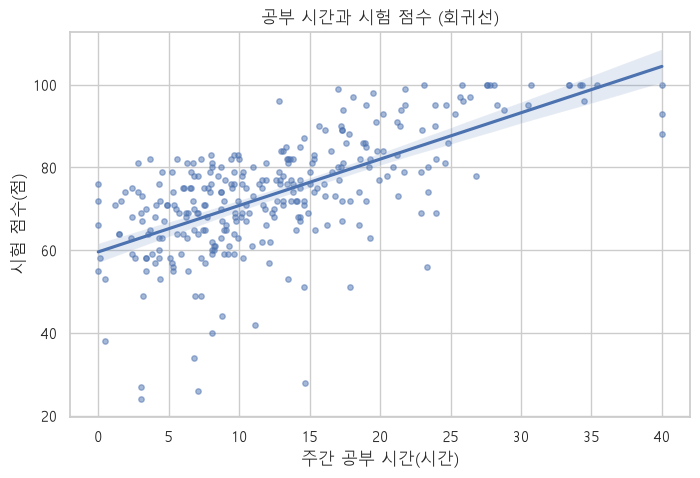

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=students, x='study_hours', y='exam_score', scatter_kws={'s': 15, 'alpha': 0.5}, ax=ax)
ax.set_title('공부 시간과 시험 점수 (회귀선)')
ax.set_xlabel('주간 공부 시간(시간)')
ax.set_ylabel('시험 점수(점)')
plt.show()

* 회귀선이 오른쪽 위로 올라간다. 공부 시간이 길수록 점수가 높은 경향이다.
  * 선의 기울기는 약 1.12다. 공부 시간이 1시간 길면 점수가 평균 1.12점쯤 높다는 뜻이다(직선 기준).
* 띠는 가운데(10~15시간)가 좁고 양 끝이 넓다. 학생이 적은 35시간 이상 쪽은 선이 더 흔들릴 수 있다.
* 점이 선에서 얼마나 떨어져 흩어졌는지는 선만으로는 알 수 없다. 이것을 숫자로 보는 것이 <b>상관계수</b>다.
  * <b>상관계수 r</b>: -1~1 사이 숫자. 부호는 방향(+ 함께 늘어남, - 한쪽이 늘면 다른 쪽이 줄어듦), 0에서 멀수록 점이 직선 가까이 모여 있다.
  * <b>열1.corr(열2)</b>: 두 열의 상관계수를 구한다. 빈 값이 있는 행은 빼고 계산한다.

In [9]:
print(round(students['study_hours'].corr(students['exam_score']), 2))
print(round(students['exam_score'].corr(students['gpa']), 2))
print(round(students['sns_minutes'].corr(students['sleep_hours']), 2))
print(round(students['part_time_hours'].corr(students['study_hours']), 2))

0.65
0.72
-0.36
-0.28


* 네 쌍의 r
  * 공부 시간-시험 점수 0.65, 시험 점수-평점 0.72: 양의 관계. 점수-평점이 직선에 조금 더 가깝게 모여 있다.
  * SNS 시간-수면 시간 -0.36: 음의 관계. SNS를 오래 쓰는 학생일수록 잠이 짧은 경향이다.
  * 아르바이트 시간-공부 시간 -0.28: 약한 음의 관계. 1)의 큰 점이 왼쪽에 조금 많았던 것과 맞다.
* r은 직선 관계만 잰다. 곡선 모양 관계나 두 갈래로 섞인 관계는 r만 보면 놓칠 수 있다. 숫자와 산점도를 함께 본다.

* 이번에는 전공별로 회귀선을 따로 그어 기울기를 비교한다. <b>sns.lmplot</b>을 쓴다.
  * <b>col='major'</b>: 전공마다 칸을 하나씩 만들어 옆으로 늘어놓는다. <b>col_order</b>로 칸 순서를 정한다.
* lmplot은 지금까지의 Seaborn 함수와 다르다.
  * 지금까지(scatterplot·regplot·histplot…): 우리가 만든 칸(Axes)에 <b>ax=</b>로 그리고, Axes를 돌려준다.
  * lmplot: Figure와 칸을 <b>스스로</b> 만들고 <b>FacetGrid</b>(칸 묶음)를 돌려준다. 그래서 <b>ax=</b>를 받지 않는다. 넣으면 <b>TypeError: lmplot() got an unexpected keyword argument 'ax'</b>가 난다.
  * 크기는 figsize 대신 <b>height</b>(칸 하나의 높이, 인치)로 정한다.
  * 칸 제목은 <b>g.set_titles('{col_name}')</b>로 단다. 글자 안의 {col_name} 자리에 그 칸의 값(공학 등)이 들어간다. 축 이름은 <b>g.set_axis_labels('x 이름', 'y 이름')</b>으로 모든 칸에 한 번에 단다.

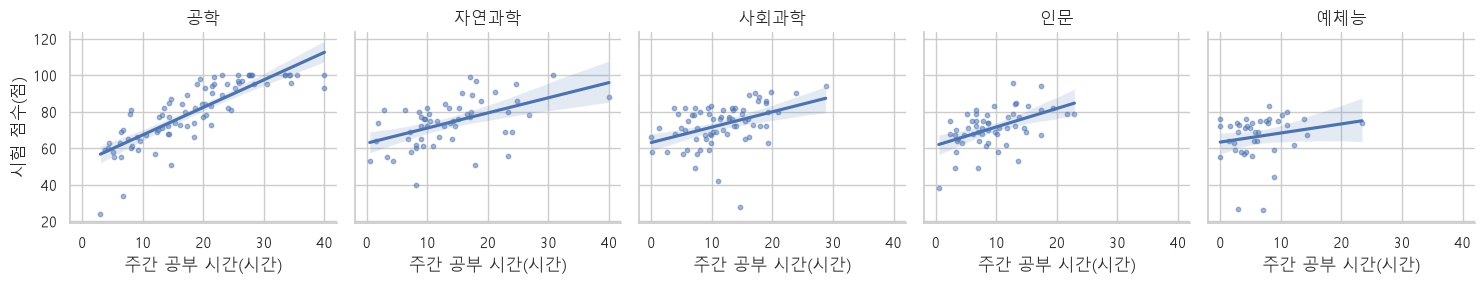

<class 'seaborn.axisgrid.FacetGrid'>


In [10]:
g = sns.lmplot(data=students, x='study_hours', y='exam_score', col='major', col_order=major_order,
               height=3, scatter_kws={'s': 10, 'alpha': 0.5})
g.set_titles('{col_name}')
g.set_axis_labels('주간 공부 시간(시간)', '시험 점수(점)')
plt.show()

print(type(g))

* 칸 다섯 개가 한 줄로 놓이고, 칸마다 그 전공 학생만으로 그은 회귀선이 있다. y축은 다섯 칸이 같아서 높이를 바로 비교할 수 있다.
* 공학 선이 가장 가파르고 예체능 선이 가장 평평하다. 기울기를 숫자로 확인한다.
  * <b>g.axes</b>: FacetGrid 안의 칸 배열. 5강 axes처럼 <b>g.axes[0, i]</b>로 i번째 칸을 꺼낸다.
  * 칸의 첫 번째 선(<b>lines[0]</b>)이 회귀선이다. 선 양 끝의 높이 차이를 가로 길이로 나누면 기울기다.

In [11]:
for i in range(5):
    x, y = g.axes[0, i].lines[0].get_data()
    print(major_order[i], round((y[-1] - y[0]) / (x[-1] - x[0]), 2))

공학 1.51
자연과학 0.83
사회과학 0.84
인문 1.01
예체능 0.5


* 공학 1.51 → 인문 1.01 → 사회과학 0.84 → 자연과학 0.83 → 예체능 0.50(점/시간). 공학이 가장 가파르다.
  * 공학 학생은 공부 시간이 1시간 길 때 점수 차이가 평균 1.5점쯤으로, 예체능(0.5점쯤)의 세 배쯤이다.
  * 사회과학 0.84와 자연과학 0.83은 거의 같다. 두 전공의 순위는 따지지 않는다.
* 예체능은 점이 0~15시간에 몰려 있어 오른쪽 띠가 넓다. 학생 수가 적고 범위가 좁으면 기울기도 더 흔들린다.

#### <b>3) 기온과 에이드·라떼 판매량 lmplot</b>

* 카페 데이터로 기온과 메뉴 판매량의 관계를 본다. 먼저 전체 365일로 회귀선을 긋는다.
  * regplot은 Axes에 그리는 함수라서 1×2 칸에 나눠 그릴 수 있다. lmplot은 칸을 스스로 만들기 때문에 이렇게 남의 칸에 넣을 수 없다.

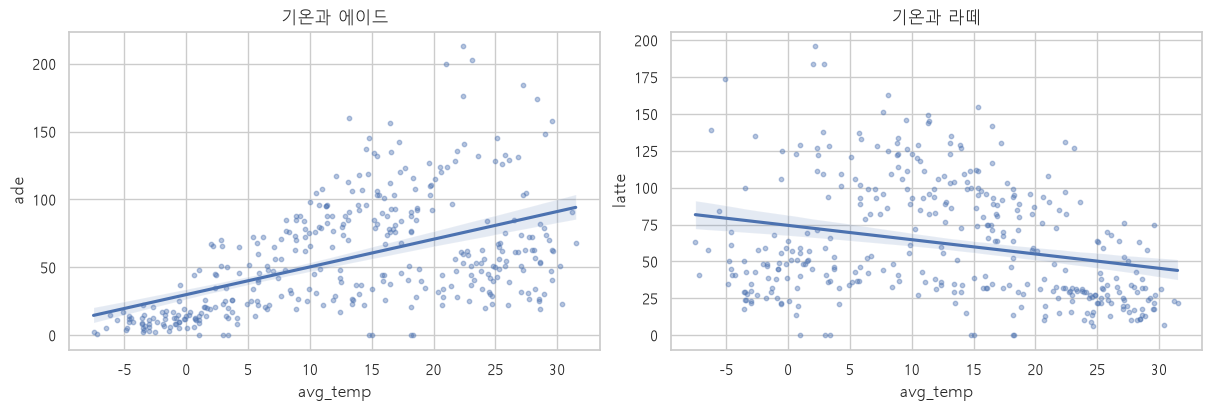

0.51 -0.25


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
sns.regplot(data=cafe, x='avg_temp', y='ade', scatter_kws={'s': 10, 'alpha': 0.4}, ax=axes[0])
axes[0].set_title('기온과 에이드')
sns.regplot(data=cafe, x='avg_temp', y='latte', scatter_kws={'s': 10, 'alpha': 0.4}, ax=axes[1])
axes[1].set_title('기온과 라떼')
plt.show()

print(round(cafe['avg_temp'].corr(cafe['ade']), 2), round(cafe['avg_temp'].corr(cafe['latte']), 2))

* 에이드 선은 오른쪽 위로(r = 0.51), 라떼 선은 오른쪽 아래로(r = -0.25) 기운다. 더운 날 에이드가 더 팔리고 라떼는 덜 팔리는 경향이다.
* 하지만 1)에서 본 것처럼 이 점들은 학기 평일과 주말·방학 두 무리가 섞여 있다. lmplot의 <b>hue='day_type'</b>으로 무리마다 회귀선을 따로 긋는다.
  * lmplot에서 hue는 점 색과 회귀선을 함께 나눈다. 칸은 하나이므로 <b>g.ax</b>로 그 칸을 꺼내 제목을 단다.

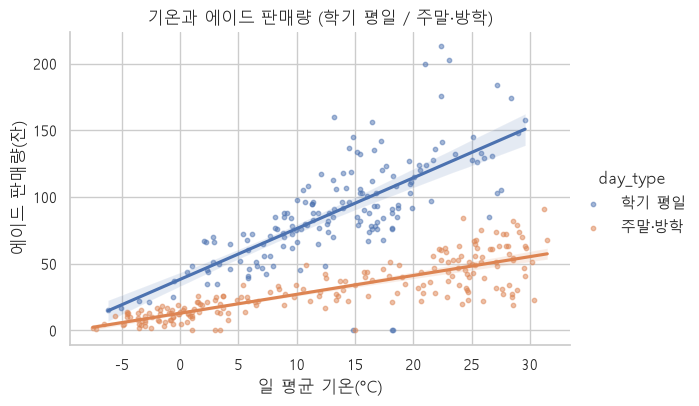

학기 평일 3.8
주말·방학 1.41


In [13]:
g = sns.lmplot(data=cafe, x='avg_temp', y='ade', hue='day_type', hue_order=day_type_order,
               height=4, aspect=1.5, scatter_kws={'s': 10, 'alpha': 0.5})
g.set_axis_labels('일 평균 기온(°C)', '에이드 판매량(잔)')
g.ax.set_title('기온과 에이드 판매량 (학기 평일 / 주말·방학)')
plt.show()

for i in range(2):
    x, y = g.ax.lines[i].get_data()
    print(day_type_order[i], round((y[-1] - y[0]) / (x[-1] - x[0]), 2))

* <b>aspect</b>: 칸의 가로 ÷ 세로 비율. height=4, aspect=1.5면 칸 하나가 가로 6인치다.
* 두 무리 모두 오른쪽 위로 올라가지만 기울기가 다르다.
  * 학기 평일: 기온 1°C당 약 3.80잔, 주말·방학: 약 1.41잔. 손님이 많은 학기 평일에는 기온에 따른 판매량 차이가 더 크다.
  * 학기 평일 선 아래쪽 바닥의 세 점은 추석 휴무일(10/6~10/8)이다.
* 무리를 나누면 상관계수도 달라진다. 무리마다 r을 구한다.

In [14]:
for day in day_type_order:
    part = cafe[cafe['day_type'] == day]
    print(day, round(part['avg_temp'].corr(part['ade']), 2), round(part['avg_temp'].corr(part['latte']), 2))

학기 평일 0.72 -0.59
주말·방학 0.82 -0.54


* 에이드: 전체 0.51 → 학기 평일 0.72, 주말·방학 0.82. 라떼: 전체 -0.25 → 학기 평일 -0.59, 주말·방학 -0.54.
  * 손님 수가 크게 다른 두 무리가 섞여 있으면, 무리 안에서는 뚜렷한 관계가 전체로는 약하게 보일 수 있다.
* 라떼도 같은 방법으로 그려 본다.
  * <b>혼자 해 보기</b>: 위 에이드 lmplot 코드에서 y를 latte로 바꾸고 제목·축 이름을 고쳐 본다.

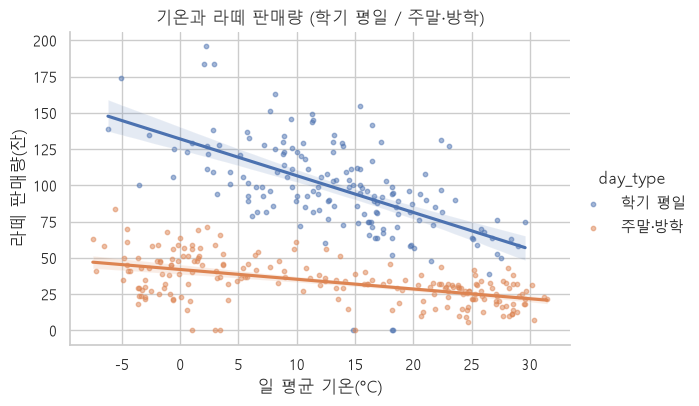

In [15]:
g = sns.lmplot(data=cafe, x='avg_temp', y='latte', hue='day_type', hue_order=day_type_order,
               height=4, aspect=1.5, scatter_kws={'s': 10, 'alpha': 0.5})
g.set_axis_labels('일 평균 기온(°C)', '라떼 판매량(잔)')
g.ax.set_title('기온과 라떼 판매량 (학기 평일 / 주말·방학)')
plt.show()

* 두 무리 모두 오른쪽 아래로 내려간다. 학기 평일 선이 더 가파르다.

* <b>상관은 인과가 아니다.</b> 두 값이 함께 움직여도 한쪽이 다른 쪽을 움직인다는 뜻은 아니다.
* 에이드와 아메리카노 판매량의 상관계수를 구해 본다.

In [16]:
print(round(cafe['ade'].corr(cafe['americano']), 2))
print(round(cafe['ade'].corr(cafe['customers']), 2))
print(round(cafe['americano'].corr(cafe['customers']), 2))

0.8
0.81
0.98


* 에이드-아메리카노 r = 0.80으로 아주 강한 양의 관계다. 그렇다고 에이드가 팔려서 아메리카노가 팔린 것은 아니다.
  * 두 메뉴 모두 손님 수와 강하게 함께 움직인다(0.81, 0.98). 손님이 많은 날(학기 평일) 둘 다 많이 팔린 것이다.
  * 이처럼 두 값을 함께 움직이는 제3의 변수가 있으면, 원인과 상관없이 r이 높게 나온다.
* 회귀선과 r은 "함께 움직이는 방향과 정도"를 보여 줄 뿐이다. 왜 그런지는 데이터가 만들어진 상황을 보고 따로 따져야 한다.

#### <b>4) 월별 손님 수 lineplot과 7일 이동평균</b>

* <b>시계열</b>: 날짜·월처럼 시간 순서로 놓인 값. cafe는 하루 = 1행인 시계열이다.
* 3강에서는 월별 평균 손님 수를 두 단계로 그렸다.
  * <b>groupby('year_month')</b>로 월별 평균 표(customers_by_month)를 만들고, <b>ax.plot</b>에 index와 values를 넘겼다.
* <b>sns.lineplot(data=표, x='열', y='열')</b>: x값마다 y의 <b>평균</b>을 계산해 선으로 잇는다. 원래 표를 그대로 넘긴다.
  * year_month('2025-03' 같은 글자)를 x로 쓰면 표에 나온 순서(2025-03 → 2026-02)대로 놓인다.
* 두 방법을 위아래 2×1 칸에 그려 비교한다. 월 글자 12개가 겹치지 않게 가로를 넓게 잡는다(3강).

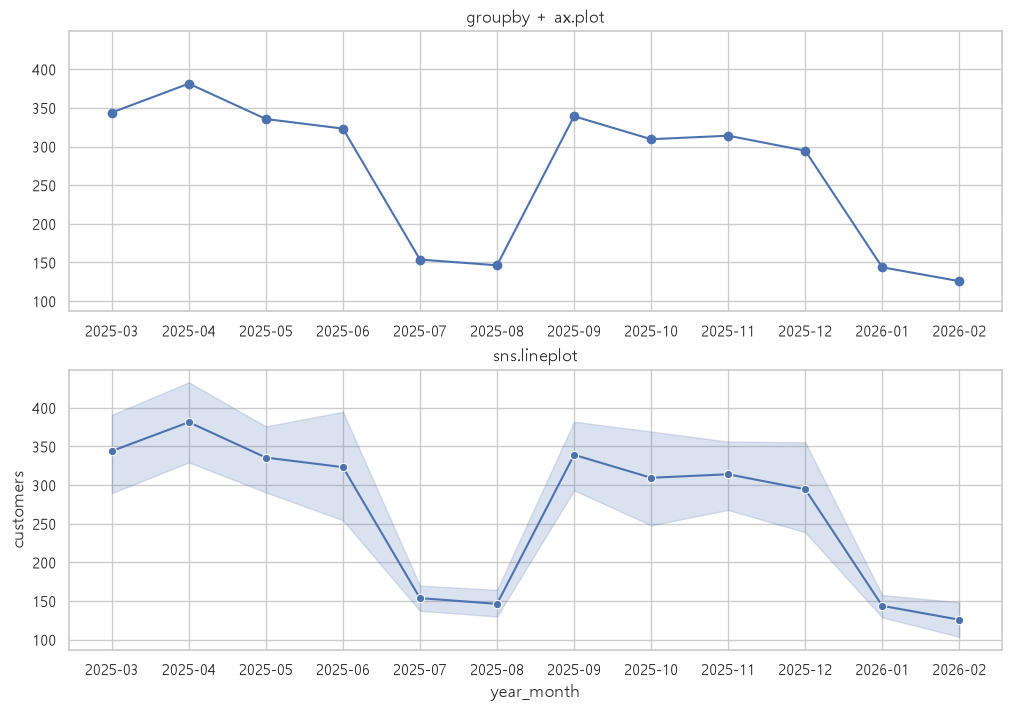

[344.   381.37 335.58 323.17 153.71 146.32 339.13 309.45 313.97 294.61
 143.74 125.79]


In [17]:
customers_by_month = cafe.groupby('year_month')['customers'].mean().round(2)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharey=True, layout='constrained')
axes[0].plot(customers_by_month.index, customers_by_month.values, marker='o')
axes[0].set_title('groupby + ax.plot')
sns.lineplot(data=cafe, x='year_month', y='customers', marker='o', ax=axes[1])
axes[1].set_title('sns.lineplot')
plt.show()

print(axes[1].lines[0].get_ydata().round(2))

* 두 선의 높이는 같다. 출력한 값이 customers_by_month와 같다(2025-04 381.37 가장 높음, 2026-02 125.79 가장 낮음).
* 아래 lineplot에는 선 둘레에 연한 <b>띠</b>가 있다.
  * 한 달에 날이 30일쯤 있어서 x값 하나에 y값이 여러 개다. lineplot은 그 평균을 선으로, 평균의 <b>95% 신뢰구간</b>을 띠로 그린다. 7강 barplot의 errorbar와 같은 기본값이다.
  * 7강처럼 <b>errorbar='sd'</b>로 표준편차 띠, <b>errorbar=None</b>으로 띠 없이 그릴 수 있다. 부트스트랩이라 seed가 없으면 띠가 실행마다 조금 달라진다.
* 띠 너비가 달마다 다르다.
  * 학기 달(3~6월, 9~12월)은 띠가 넓고, 방학 달(7·8월, 1월)은 좁다. 학기 달에는 평일(약 410명)과 주말(약 150명)이 섞여 값이 넓게 퍼지기 때문이다.

* 이번에는 월 평균 대신 <b>일별</b> 손님 수를 그대로 그린다. x에 date를 주면 x값 하나에 값이 하나라 띠가 생기지 않는다.
* 일별 선은 평일·주말에 따라 매주 크게 오르내려서 큰 흐름이 잘 안 보인다.
* <b>이동평균</b>: 날마다 "오늘 포함 지난 며칠"의 평균을 다시 구한 값. 짧은 출렁임을 걸러 추세만 남긴다.
  * <b>열.rolling(7).mean()</b>: 행마다 그 행과 바로 위 6행(모두 7행)의 평균을 낸다. cafe는 하루 = 1행이라 7일 이동평균이다.
  * 처음 6일은 7일치가 모이지 않아 빈 값(NaN)이 된다.
  * 끝의 <b>round(2)</b>는 2강처럼 소수 둘째 자리까지 반올림한다.

In [18]:
cafe['customers_7d'] = cafe['customers'].rolling(7).mean().round(2)
cafe[['date', 'weekday', 'customers', 'customers_7d']].head(8)

,date,weekday,customers,customers_7d
0,2025-03-01,토,169,NaN
1,2025-03-02,일,157,NaN
2,2025-03-03,월,485,NaN
3,2025-03-04,화,419,NaN
4,2025-03-05,수,522,NaN
5,2025-03-06,목,459,NaN
6,2025-03-07,금,308,359.86
7,2025-03-08,토,158,358.29


* 0~5행(3/1~3/6)은 NaN이다. 3/7 값 359.86은 3/1~3/7 손님 수의 평균이다.
* 일별 선은 흐리게(<b>alpha=0.3</b>), 이동평균 선은 진하게 같은 칸에 겹쳐 그린다. <b>label=</b>로 범례 이름을 단다.
  * lineplot은 빈 값을 건너뛰고 그리므로 처음 6일은 이동평균 선이 없다.

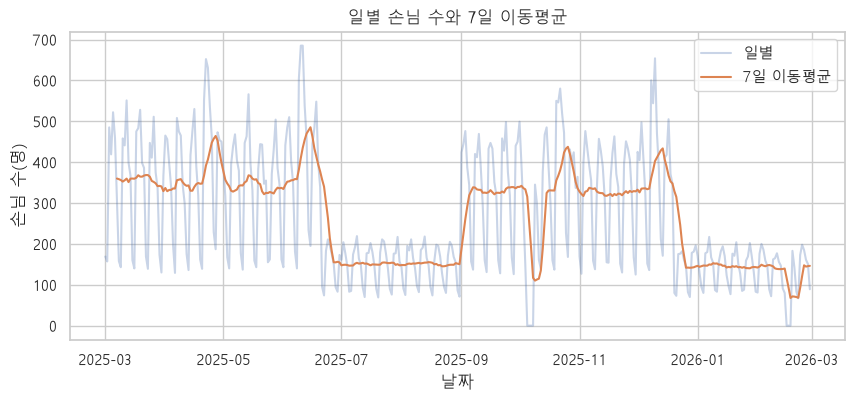

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=cafe, x='date', y='customers', alpha=0.3, label='일별', ax=ax)
sns.lineplot(data=cafe, x='date', y='customers_7d', label='7일 이동평균', ax=ax)
ax.set_title('일별 손님 수와 7일 이동평균')
ax.set_xlabel('날짜')
ax.set_ylabel('손님 수(명)')
plt.show()

* 그래프에서 읽을 것
  * 일별 선(흐림)은 매주 평일에 오르고 주말에 떨어지는 톱니 모양이다.
  * 이동평균 선(진함)은 톱니가 사라지고 학기에 높고 방학(7·8월, 1·2월)에 낮은 큰 흐름만 남는다.
  * 4월 말·6월 중순·10월 말·12월 중순에 이동평균이 솟는다. 네 번의 시험 주간이다(5강 주석).
  * 10월 초와 2월 중순에는 이동평균이 움푹 꺼진다. 추석·설 연휴 휴무일의 0이 들어간 주다.
* 이동평균이 가장 높은 날과 가장 낮은 날을 2강의 <b>sort_values</b>로 확인한다. 빈 값은 정렬 맨 뒤로 간다.

In [20]:
print(cafe.sort_values('customers_7d', ascending=False)[['date', 'customers_7d']].head(3))
print(cafe.sort_values('customers_7d')[['date', 'customers_7d']].head(3))

          date  customers_7d
106 2025-06-15        485.29
105 2025-06-14        477.43
104 2025-06-13        470.00
          date  customers_7d
354 2026-02-18         67.71
358 2026-02-22         68.14
357 2026-02-21         70.00


* 가장 높은 날은 2025-06-15(485.29명)다. 6/9~6/15 기말 시험 주간 7일이 꼭 맞게 들어간 평균이다.
* 가장 낮은 날은 2026-02-18(67.71명)이다. 설 연휴 휴무일(2/16~2/18) 세 날의 0이 7일 평균에 들어가 있다.
* 오늘 정리: <b>scatterplot</b>은 관계와 세 번째 변수, <b>regplot·lmplot</b>은 관계의 방향(상관계수로 강도), <b>lineplot</b>은 시간에 따른 평균과 범위, <b>rolling</b>은 출렁임을 걸러낸 추세를 보여 준다.